# Station demand prediction: data, features and evaluation setup

This notebook walks through the prediction track step by step: why we need it,
the data and its cleaning, the features, and how the models are evaluated.

**Before running**, the cached files must exist (see the README, "Demand prediction"):

```bash
python -m prediction.trips --routes ../Routes/routes_2025.csv
python -m prediction.demand
python -m prediction.weather
python -m prediction.evaluate
```

In [30]:
import sqlite3
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent  
sys.path.insert(0, str(ROOT))
PROJECT = ROOT.parent

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from prediction import calendar, features, outages, trips as trips_module, weather
from prediction.baselines import HistoricalMean
from prediction.evaluate import TEST_START, VALID_START, read_demand, split

CACHE = ROOT / "cache" / "prediction"
TZ = "Europe/Tallinn"
pd.set_option("display.width", 160)


BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GRAY, INK, INK2, GRID = "#8a8984", "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "font.size": 10, "axes.titlesize": 12, "axes.titlelocation": "left", "axes.titlecolor": INK,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": "#bdbcb6", "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID,
    "axes.axisbelow": True, "xtick.major.size": 0, "ytick.major.size": 0, "legend.frameon": False,
})

## 1. Why: stations run empty

Our poller (`poller/`) asks the public station API every 5 minutes how many
bikes each station has. One snapshot from Tuesday 27 Oct 2026, 19:29:
**18 of 110 stations had no bikes at all**. 

The goal of this track is to see this coming: forecast pickups and returns per
station hours ahead, so the operator can move bikes before a station empties.

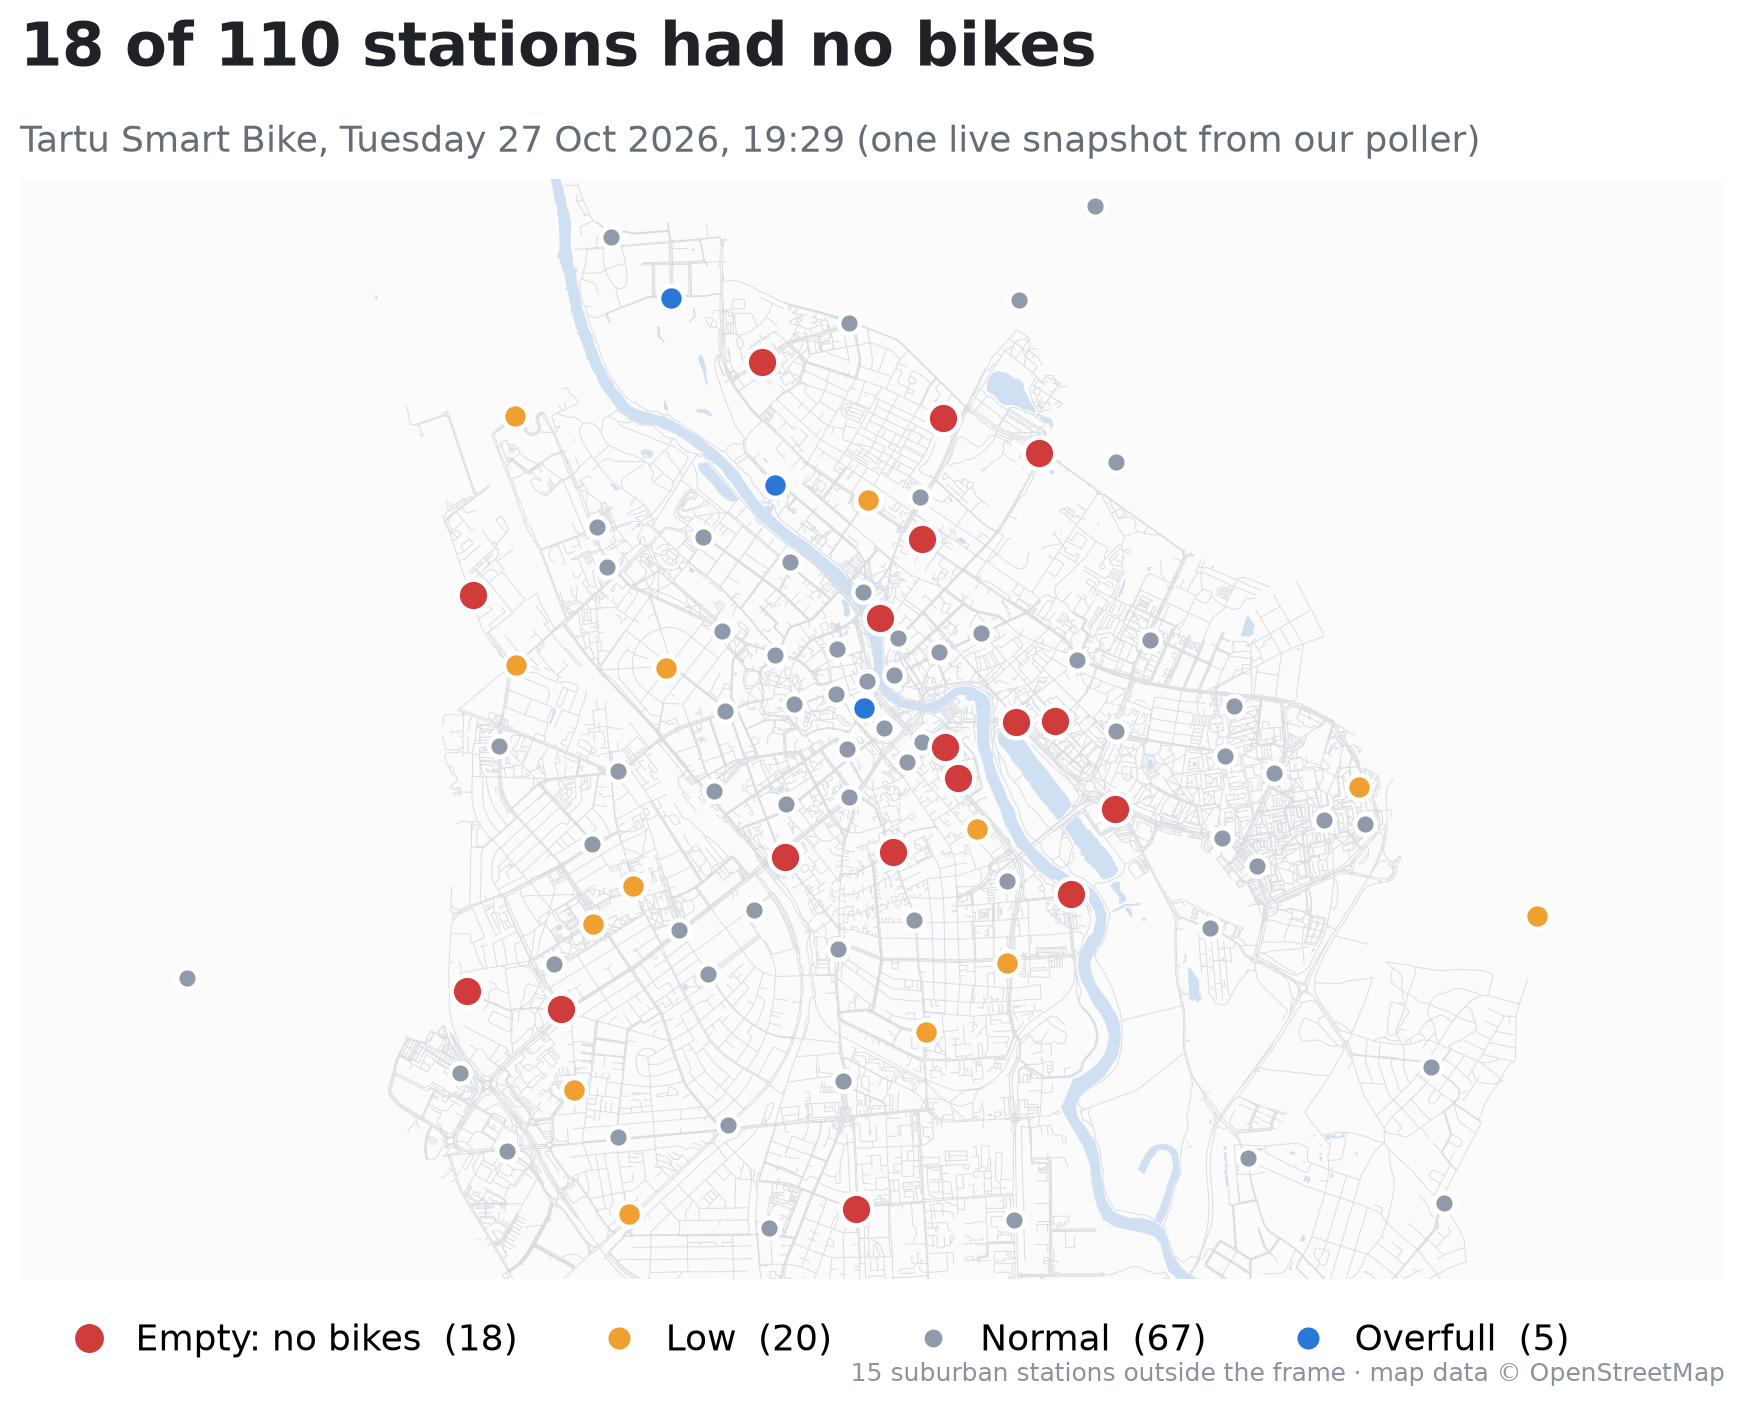

In [31]:
display(Image(filename=str(PROJECT / "slides_figures" / "7_empty_stations_snapshot.png"), width=650))

The local copy of the poller database (a test run, 30–31 Oct 2026) shows this is
not a one-off: empty stations are there all the time, and the same stations are
empty again and again. The full history is on the poller's server.

152 polls, 30 Oct 21:35 – 31 Oct 10:10 (Tallinn time)
empty stations per poll: min 9, median 13, max 16
stations empty in more than half of the polls: 13


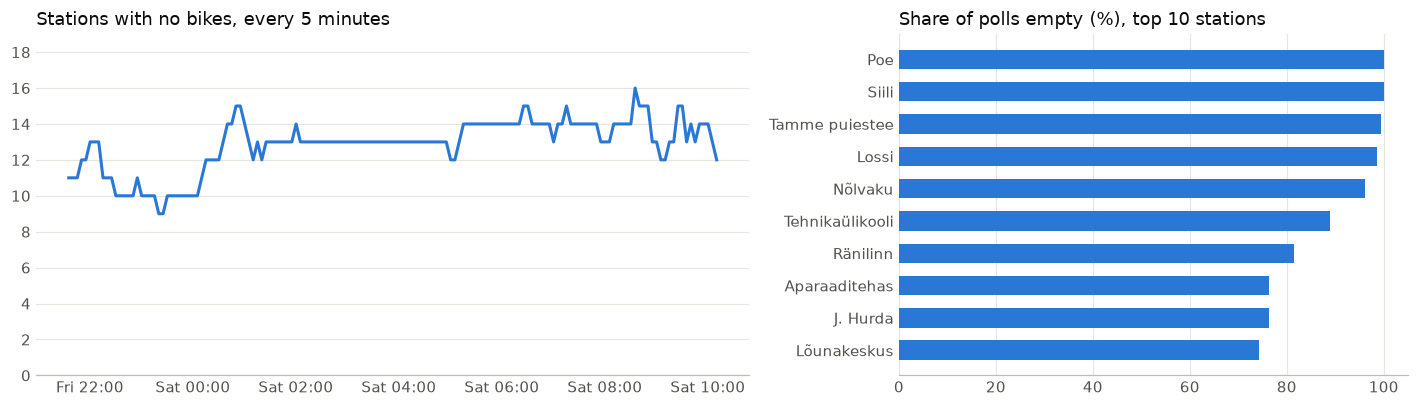

In [32]:
db_path = PROJECT / "station_status.sqlite3"
with sqlite3.connect(db_path) as connection:
    status = pd.read_sql(
        "select polled_at, station_id, station_name, bikes_total from station_status", connection
    )
status["polled_at"] = pd.to_datetime(status["polled_at"], utc=True).dt.tz_convert(TZ)
per_poll = status.groupby("polled_at").agg(
    empty=("bikes_total", lambda bikes: int((bikes == 0).sum())), stations=("station_id", "nunique")
)
share_empty = (
    status.assign(empty=status["bikes_total"] == 0)
    .groupby("station_name")["empty"].mean().sort_values(ascending=False)
)
print(f"{len(per_poll)} polls, {per_poll.index.min():%d %b %H:%M} – {per_poll.index.max():%d %b %H:%M} (Tallinn time)")
print(f"empty stations per poll: min {per_poll['empty'].min()}, median {per_poll['empty'].median():.0f}, max {per_poll['empty'].max()}")
print(f"stations empty in more than half of the polls: {(share_empty > 0.5).sum()}")

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.4, 1]})
left.plot(per_poll.index, per_poll["empty"], color=BLUE, lw=2)
left.set_ylim(0, per_poll["empty"].max() + 3)
left.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
left.set_title("Stations with no bikes, every 5 minutes")
left.xaxis.set_major_formatter(mdates.DateFormatter("%a %H:%M", tz=TZ))
top = share_empty.head(10)[::-1]
right.barh(top.index, top.values * 100, color=BLUE, height=0.6)
right.set_title("Share of polls empty (%), top 10 stations")
right.grid(axis="x", color=GRID)
right.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 2. The data: 2025 trips

Code: [prediction/trips.py](../prediction/trips.py).

The forecast does not use single trips. It uses **how many bikes left (pickups)
and arrived (returns) at each station in each hour**.

,2025
trips (after cleaning),"656,183"
bikes,803
stations used,106
first trip,01 Jan 2025
last trip,31 Dec 2025
median duration,11 min


,trips
CycleType,
Pedelec,607668
Bike,48515


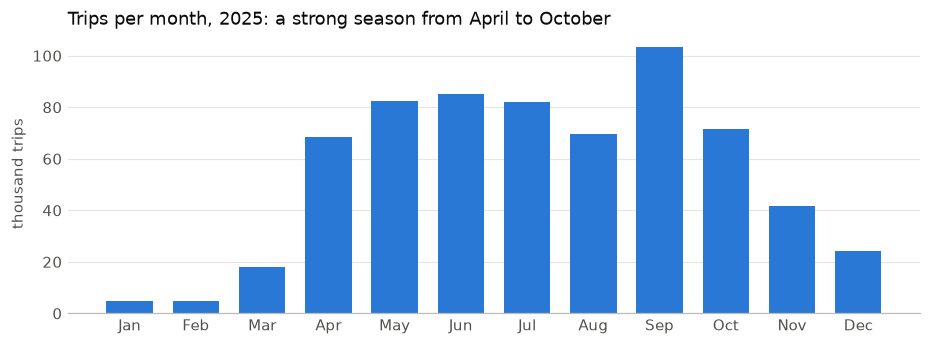

In [33]:
trips = pd.read_csv(CACHE / "trips_2025.csv.gz", usecols=["CycleNumber", "StartStationSerialNumber", "EndStationSerialNumber", "start_local", "DurationMinutes", "CycleType"])
trips["start_local"] = pd.to_datetime(trips["start_local"], utc=True).dt.tz_convert(TZ)

summary = pd.Series({
    "trips (after cleaning)": f"{len(trips):,}",
    "bikes": f"{trips['CycleNumber'].nunique():,}",
    "stations used": trips["StartStationSerialNumber"].nunique(),
    "first trip": f"{trips['start_local'].min():%d %b %Y}",
    "last trip": f"{trips['start_local'].max():%d %b %Y}",
    "median duration": f"{trips['DurationMinutes'].median():.0f} min",
})
display(summary.to_frame("2025"))
display(trips["CycleType"].value_counts().rename("trips").to_frame())

monthly = trips.groupby(trips["start_local"].dt.month).size()
fig, ax = plt.subplots(figsize=(10, 3.3))
ax.bar(monthly.index, monthly.values / 1000, color=BLUE, width=0.7)
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylabel("thousand trips")
ax.set_title("Trips per month, 2025: a strong season from April to October")
plt.show()

## 3. Cleaning

Rules from Tartu Smart Bike (Kärt Lang), plus one of ours. Each trip gets the
**first** rule that applies (`drop_reason` in [prediction/trips.py](../prediction/trips.py)):

| Rule | Why |
|---|---|
| missing time or bike | cannot be placed in time |
| ends or starts at **Töökoda** | ended in the workshop: faulty bike |
| **undetermined** start or end station | outside any station area: usually a faulty bike |
| **aborted**: length 0 or under 2 minutes | an unlock without a ride (Kärt: under 30 s is faulty; we use a stricter 2 min) |
| longer than 5 hours | not allowed, system or user error: **kept but flagged** (`too_long`) |

The cell below re-runs the cleaning on the raw export if it is available (about a minute).

In [34]:
raw_file = trips_module.DEFAULT_ROUTES_FILE
if raw_file.exists():
    raw = trips_module.load_trips(raw_file)
    kept, dropped = trips_module.clean_trips(raw)
    n_raw, n_kept, n_long = len(raw), len(kept), int(kept["too_long"].sum())
    del raw, kept
else:  # numbers from the last run (27 Oct 2026)
    dropped = pd.Series({"aborted": 84_489, "undetermined_station": 5_964, "workshop": 163, "missing_time_or_bike": 15})
    n_raw, n_kept, n_long = 746_814, 656_183, 361

table = dropped.rename("trips").to_frame()
table["share of raw"] = (table["trips"] / n_raw).map("{:.1%}".format)
table.loc["kept"] = [n_kept, f"{n_kept / n_raw:.1%}"]
table.loc["  of which too_long (flagged)"] = [n_long, f"{n_long / n_raw:.2%}"]
print(f"raw trips: {n_raw:,}")
display(table)

raw trips: 746,814


,trips,share of raw
aborted,84489,11.3%
undetermined_station,5964,0.8%
workshop,163,0.0%
missing_time_or_bike,15,0.0%
kept,656183,87.9%
of which too_long (flagged),361,0.05%


**Time zone finding.** The export's times are **UTC+2 all year**, not Estonian
clock time (which is UTC+3 in summer). Proof: `RouteCode` is the unlock moment in
UTC milliseconds and is always exactly 2 h behind the export time, and the
weekday morning peak "jumps" by one hour in the weeks the clocks change. After
the fix (`export_time_to_utc`), the peak stays at 8:00 all year:

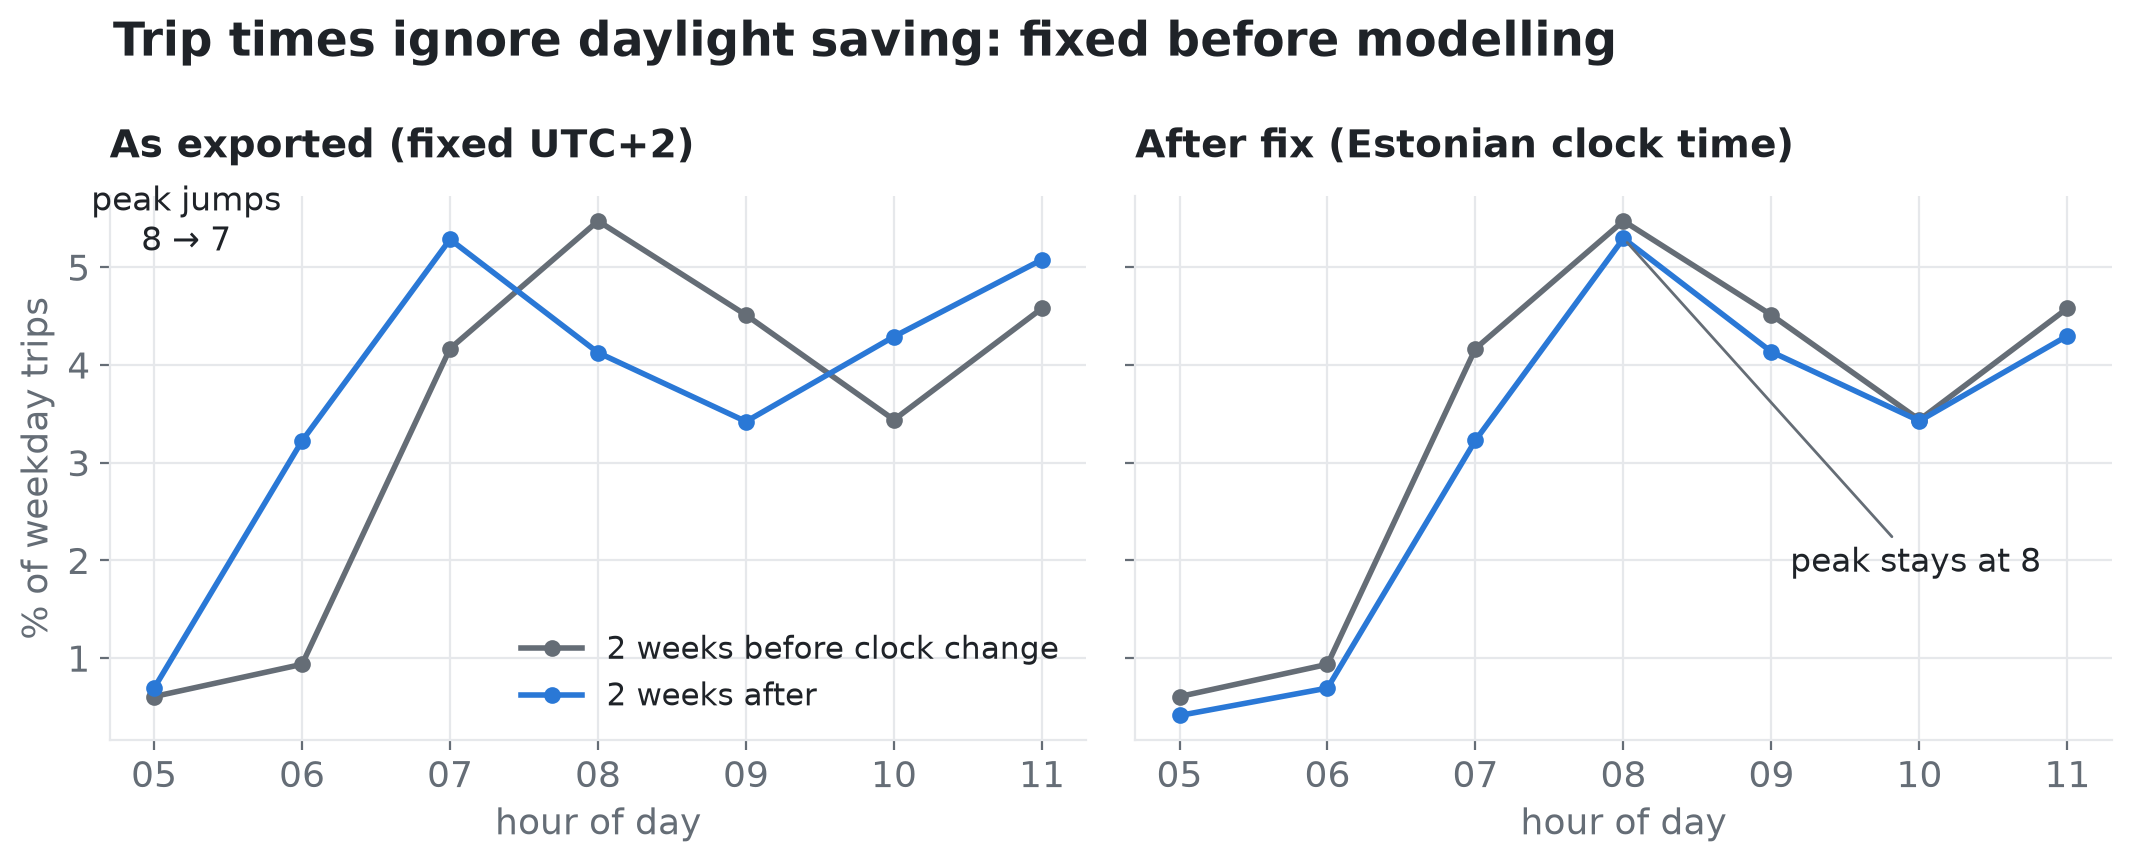

In [35]:
display(Image(filename=str(PROJECT / "slides_figures" / "3_timezone_fix.png"), width=650))

### From trips to the demand table

[prediction/demand.py](../prediction/demand.py) counts, for every station and
every hour it was in use, the **pickups** (trips starting there) and **returns**
(trips ending there). Hours without trips are 0, not missing. Stations used on
fewer than 7 days (temporary event stations) are left out. Hours are keyed in UTC,
because local time has a 23-hour and a 25-hour day.

898,674 station-hours, 105 stations modelled (1 short-lived stations left out)


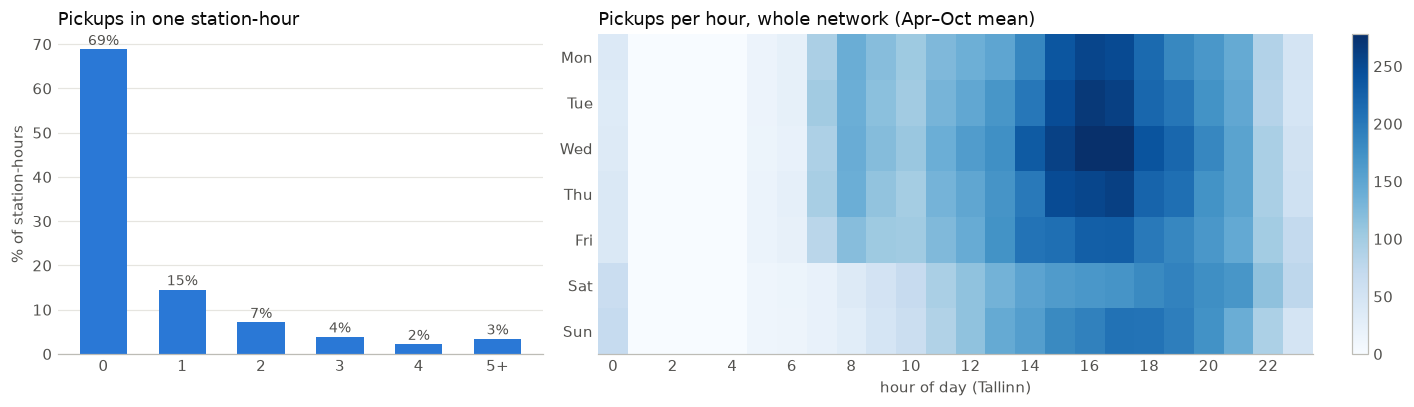

In [36]:
demand = read_demand()
stations = pd.read_csv(CACHE / "stations_2025.csv")
print(f"{len(demand):,} station-hours, {demand['station'].nunique()} stations modelled "
      f"({(~stations['modelled']).sum()} short-lived stations left out)")

counts = demand["pickups"].clip(upper=5).value_counts(normalize=True).sort_index()
local = demand["hour_utc"].dt.tz_convert(TZ)
season = demand[local.dt.month.between(4, 10)]
season_local = season["hour_utc"].dt.tz_convert(TZ)
network = season.groupby([season_local.dt.date, season_local.dt.weekday, season_local.dt.hour])["pickups"].sum()
heat = network.groupby(level=[1, 2]).mean().unstack()

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
left.bar([str(k) if k < 5 else "5+" for k in counts.index], counts.values * 100, color=BLUE, width=0.6)
left.set_title("Pickups in one station-hour")
left.set_ylabel("% of station-hours")
for x, value in enumerate(counts.values):
    left.text(x, value * 100 + 1, f"{value:.0%}", ha="center", color=INK2, fontsize=9)
image = right.imshow(heat.values, aspect="auto", cmap="Blues")
right.set_yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
right.set_xticks(range(0, 24, 2))
right.set_xlabel("hour of day (Tallinn)")
right.set_title("Pickups per hour, whole network (Apr–Oct mean)")
right.grid(False)
fig.colorbar(image, ax=right, fraction=0.03)
plt.tight_layout()
plt.show()

**Insights**
- **70 % of station-hours have no pickup at all**, and almost all the rest have 1–2.
  So per station and hour, demand is a small, very noisy count. This limits how
  accurate any hourly forecast can be (section 5).
- Workdays have two commute peaks (8:00 and 16–18:00). Weekends have one broad
  afternoon peak. The network is closed 01–05 h.

## 4. Features

Every row of the model table is one **station × hour**. What the model sees for
that row (built in [prediction/features.py](../prediction/features.py), `build_features`):

| Group | Features | Code |
|---|---|---|
| Calendar | hour, weekday, `is_holiday`, `is_day_off`, `is_semester` | [prediction/calendar.py](../prediction/calendar.py) |
| Weather | temperature, precipitation, snowfall, snow depth, wind, cloud cover, daylight | [prediction/weather.py](../prediction/weather.py) |
| Recent counts (lags) | the station's own pickups and returns in recent hours, days and weeks, plus the whole network's | [prediction/features.py](../prediction/features.py) |
| Outage mask | not a feature: marks hours where data is missing | [prediction/outages.py](../prediction/outages.py) |

### 4.1 Calendar

`calendar_features()` turns each local timestamp into hour, weekday and three flags:

- `is_holiday`: Estonian public holidays. Fixed dates plus Good Friday, Easter and Pentecost,
  which move every year; `easter_sunday()` computes Easter, so any year works.
- `is_day_off`: weekend **or** holiday. Holidays behave like Sundays (no commute), and
  there are only a dozen of them in a year, so sharing them with weekends lets the model learn them.
- `is_semester`: University of Tartu teaching period (dates in `SEMESTERS`, approximate, to be checked).

date,2025-01-01,2025-02-24,2025-04-18,2025-04-20,2025-05-01,2025-06-08,2025-06-23,2025-06-24,2025-08-20,2025-12-24,2025-12-25,2025-12-26
weekday,Wednesday,Monday,Friday,Sunday,Thursday,Sunday,Monday,Tuesday,Wednesday,Wednesday,Thursday,Friday


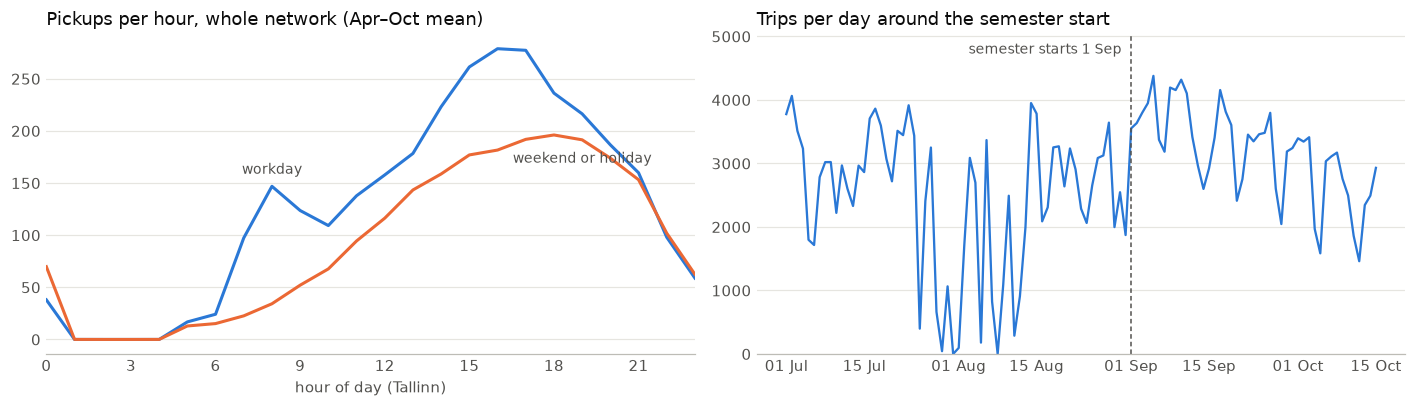

In [37]:
holidays = sorted(calendar.estonian_holidays(2025))
display(pd.DataFrame({"date": holidays, "weekday": [day.strftime("%A") for day in holidays]}).set_index("date").T)

hours = demand.groupby("hour_utc", as_index=False)[["pickups"]].sum()
hours = hours[~hours["hour_utc"].isin(outages.outage_hours(demand))]
hour_local = hours["hour_utc"].dt.tz_convert(TZ)
hours = pd.concat([hours, calendar.calendar_features(hour_local)], axis=1)
hours["date"] = hour_local.dt.date
in_season = hour_local.dt.month.between(4, 10)
profile = hours[in_season].groupby(["is_day_off", "hour"])["pickups"].mean().unstack(0)

daily = hours.groupby("date").agg(pickups=("pickups", "sum"), is_semester=("is_semester", "first"))
daily.index = pd.to_datetime(daily.index)
around = daily.loc["2025-07-01":"2025-10-15"]

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 3.8))
for flag, color, label, at, dy in [(0, BLUE, "workday", 8, 12), (1, ORANGE, "weekend or holiday", 19, -22)]:
    left.plot(profile.index, profile[flag], color=color, lw=2)
    left.text(at, profile.loc[at, flag] + dy, label, color=INK2, ha="center", fontsize=9)
left.set_xlim(0, 23)
left.set_xticks(range(0, 24, 3))
left.set_xlabel("hour of day (Tallinn)")
left.set_title("Pickups per hour, whole network (Apr–Oct mean)")
right.plot(around.index, around["pickups"], color=BLUE, lw=1.5)
right.axvline(pd.Timestamp("2025-09-01"), color=INK2, lw=1, ls=(0, (3, 2)))
right.set_ylim(0, around["pickups"].max() * 1.15)
right.text(pd.Timestamp("2025-08-31"), around["pickups"].max() * 1.08, "semester starts 1 Sep ", color=INK2, fontsize=9, ha="right")
right.set_title("Trips per day around the semester start")
right.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
plt.tight_layout()
plt.show()

**Insights**
- Days off have no 8:00 peak and a later, broader afternoon. That is why
  `is_day_off` (weekend or holiday) is a useful flag.
- The busiest weeks of the year start right after **1 September**, when students
  return. The July–August dip is partly the summer, partly the data gap (4.3).
- In the model, the calendar flags carry little weight: hour and weekday matter, but
  the lags (4.4) already know whether a day is busy. One year has too few holidays
  to learn them well, and more years of data would help here.

### 4.2 Weather

[prediction/weather.py](../prediction/weather.py) downloads hourly weather for
Tartu from the free **Open-Meteo** archive (`python -m prediction.weather`, one HTTP request,
no API key) into `cache/prediction/weather_2025.csv`, keyed by UTC hour.

Note: training and testing use *observed* weather. A live system would use the weather
*forecast*, which is less accurate, so our test scores are slightly optimistic about weather.

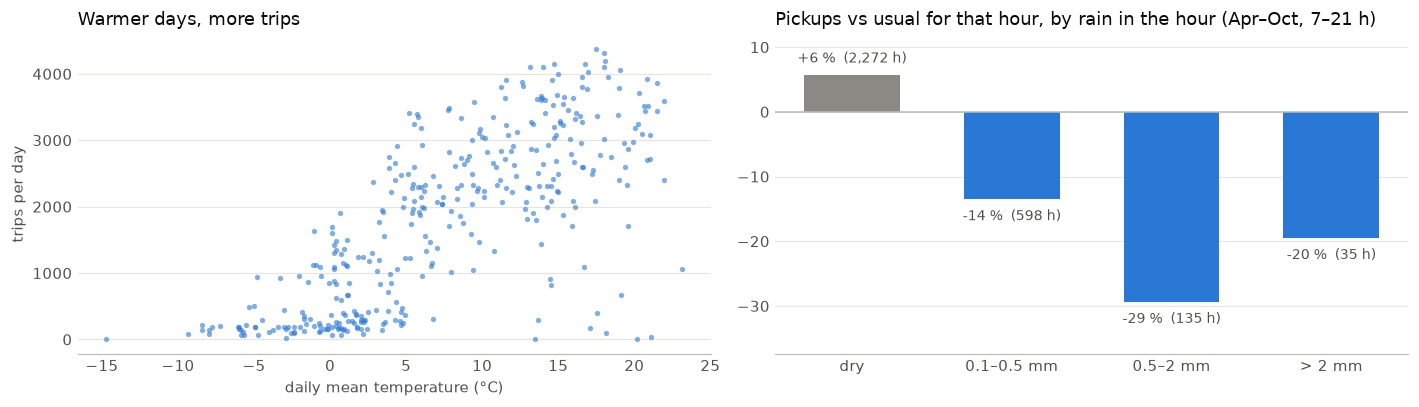

In [38]:
wx = weather.read_weather()
hours_wx = hours.merge(wx, on="hour_utc", how="left")
day = hours_wx.groupby("date").agg(pickups=("pickups", "sum"), temperature=("temperature_2m", "mean"),
                                   rain=("precipitation", "sum"), is_day_off=("is_day_off", "first"))

# Rain effect: daytime hours in the season, compared with the usual count for the same month, day type and hour.
season_hours = hours_wx[pd.to_datetime(hours_wx["date"]).dt.month.between(4, 10) & hours_wx["hour"].between(7, 21)].copy()
season_hours["month"] = pd.to_datetime(season_hours["date"]).dt.month
season_hours["usual"] = season_hours.groupby(["month", "is_day_off", "hour"])["pickups"].transform("mean")
season_hours["ratio"] = season_hours["pickups"] / season_hours["usual"]
bins = pd.cut(season_hours["precipitation"], [-0.01, 0, 0.5, 2, 100], labels=["dry", "0.1–0.5 mm", "0.5–2 mm", "> 2 mm"])
rain = season_hours.groupby(bins, observed=True)["ratio"].agg(["mean", "size"])

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 3.8))
left.scatter(day["temperature"], day["pickups"], s=12, color=BLUE, alpha=0.6, linewidths=0)
left.set_xlabel("daily mean temperature (°C)")
left.set_ylabel("trips per day")
left.set_title("Warmer days, more trips")
right.bar(rain.index.astype(str), (rain["mean"] - 1) * 100, color=[GRAY, BLUE, BLUE, BLUE], width=0.6)
right.axhline(0, color="#bdbcb6", lw=1)
for x, (value, n) in enumerate(zip(rain["mean"], rain["size"])):
    change = (value - 1) * 100
    right.text(x, change + (1.5 if change > 0 else -1.5), f"{change:+.0f} %  ({n:,} h)", ha="center",
               va="bottom" if change > 0 else "top", color=INK2, fontsize=9)
right.set_ylim((rain["mean"].min() - 1) * 100 - 8, 12)
right.set_title("Pickups vs usual for that hour, by rain in the hour (Apr–Oct, 7–21 h)")
plt.tight_layout()
plt.show()

**Insights**
- Temperature and season go together: below about 0 °C there are only a few
  hundred trips a day, above 15 °C mostly 2,000–4,500. (The near-zero warm days are
  the outage days of 4.3.) Part of the winter low may be fewer bikes on the street, not only the cold.
- Any rain in the hour cuts pickups by roughly 15–30 % compared with a usual hour.
  The "> 2 mm" group has only 35 hours, so its value is uncertain; it does not show
  that heavy rain matters less.
- Still, weather adds only ~3–4 % of the model's gain. Recent counts (4.4)
  already reflect most of the season and the weather of the last hours.

### 4.3 Outage mask

Between 25 Jul and 16 Aug 2025 the export has **blocks of hours with (almost) no
trips**, while the hours around them are normal. This is missing data, not low demand.
If the model learned these hours as "zero demand", it would under-forecast.

`outage_hours()` in [prediction/outages.py](../prediction/outages.py) flags an hour when
the **whole network** has under 20 % of the usual pickups for that weekday and hour
(usual = median of the 4 weeks before and after the window). Hours whose usual count is
under 15 (the 01–05 h night closure) are never flagged. Flagged hours are dropped from
training and testing, and lag features that would read them become missing.

220 outage hours on 17 days


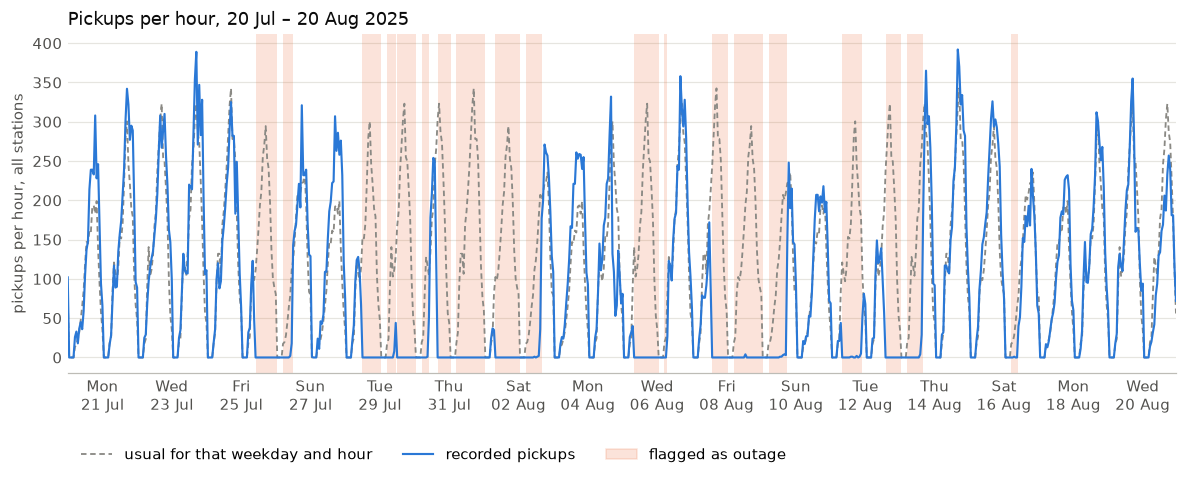

In [39]:
flagged = outages.outage_hours(demand)
flagged_local = flagged.tz_convert(TZ)
print(f"{len(flagged)} outage hours on {len(set(flagged_local.date))} days")

net = outages.network_hourly(demand)
start, end = outages.OUTAGE_WINDOW
span = pd.Timedelta(weeks=outages.REFERENCE_WEEKS)
t = net["hour_utc"]
reference = net[((t >= start - span) & (t < start)) | ((t >= end) & (t < end + span))]
net = net.join(reference.groupby(["weekday", "hour"])["pickups"].median().rename("usual"), on=["weekday", "hour"])
net["local"] = t.dt.tz_convert(TZ).dt.tz_localize(None)
show = net[(net["local"] >= "2025-07-20") & (net["local"] < "2025-08-21")]

fig, ax = plt.subplots(figsize=(13, 4))
for hour in show.loc[show["hour_utc"].isin(flagged), "local"]:
    ax.axvspan(hour, hour + pd.Timedelta(hours=1), color=ORANGE, alpha=0.18, lw=0)
ax.plot(show["local"], show["usual"], color=GRAY, lw=1.2, ls=(0, (3, 2)), label="usual for that weekday and hour")
ax.plot(show["local"], show["pickups"], color=BLUE, lw=1.4, label="recorded pickups")
ax.fill_between([], [], color=ORANGE, alpha=0.18, label="flagged as outage")
ax.set_xlim(show["local"].min(), show["local"].max())
ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a\n%d %b"))
ax.set_ylabel("pickups per hour, all stations")
ax.set_title("Pickups per hour, 20 Jul – 20 Aug 2025")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.18), ncol=3)
plt.show()

**Insights**
- 220 hours are flagged. Most of them are in 25 Jul – 13 Aug, plus 16 Aug 05–09
  (0 pickups on a dry Saturday morning).
- The gaps start and end abruptly, sometimes in the middle of a busy day. Holidays
  would lower the whole curve instead. Asked Tartu Smart Bike to confirm.

### 4.4 Recent counts (lag features) and the forecast horizon

A forecast for hour **T** made **h hours ahead** may only use trips up to hour
**T − h** (the newest finished hour). Each horizon h gets its own feature table and model.
For both pickups and returns of the station:

| Feature | Meaning (counts of this station) |
|---|---|
| `*_last` | in hour T − h |
| `*_recent3`, `*_recent24` | sum over the 3 / 24 hours ending at T − h |
| `*_day` | same hour on the latest fully known day (T − 24, or T − 48 if h > 24) |
| `*_week` | same hour one week earlier (T − 168) |
| `*_4w` | mean of the same hour over the last 4 weeks |
| `net_*_recent3` | the whole network's 3-hour sum: a sudden shower shows up here first |

`tests/test_features.py` checks that no feature reads past T − h.
The chart shows how strongly each feature moves together with the pickups to forecast
(training data, h = 3 h):

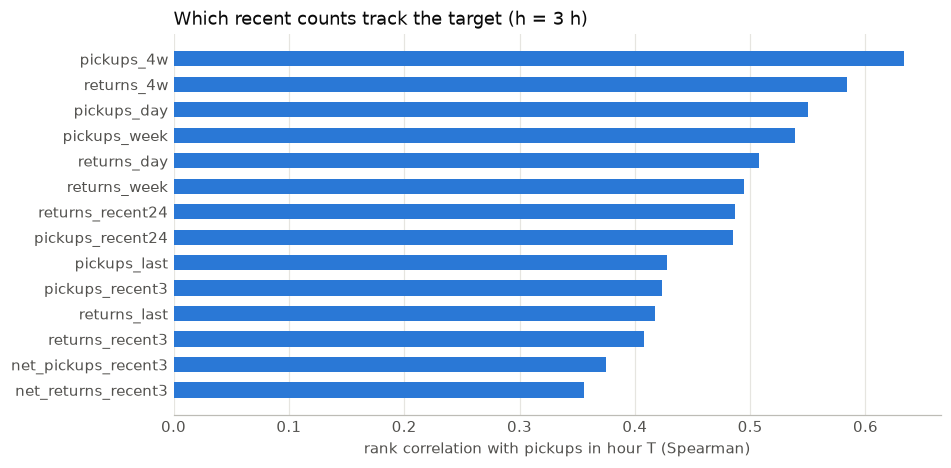

In [40]:
table = features.build_features(demand, wx, flagged, horizon=3)
train, valid, test = split(table)
lag_columns = [c for c in features.FEATURE_COLUMNS if c.startswith(("pickups_", "returns_", "net_"))]
correlation = train[lag_columns + ["pickups"]].corr(method="spearman")["pickups"].drop("pickups").sort_values()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(correlation.index, correlation.values, color=BLUE, height=0.6)
ax.set_xlabel("rank correlation with pickups in hour T (Spearman)")
ax.set_title("Which recent counts track the target (h = 3 h)")
ax.grid(axis="x", color=GRID)
ax.grid(axis="y", visible=False)
plt.show()

**Insight:** the station's usual level at this hour (`pickups_4w`, `returns_4w`)
tracks the target best: busy stations stay busy. Recent hours add short-term
information (weather, events). The model learns how to combine them.

## 5. Baselines and evaluation setup

### Split by time, never at random
With a random split, the hours around a test hour (same weather, same events) would
be in the training data, and the score would look better than it is in reality.

| Part | Period | Used for |
|---|---|---|
| train | 1 Jan – 31 Aug 2025 | fitting |
| validation | September | choosing the number of trees (early stopping) |
| test | 1 Oct – 31 Dec 2025 | final scores, never seen before |

Baselines and the final LightGBM model are fitted on train + validation (Jan–Sep).
Outage hours are excluded everywhere. Code: [prediction/evaluate.py](../prediction/evaluate.py).

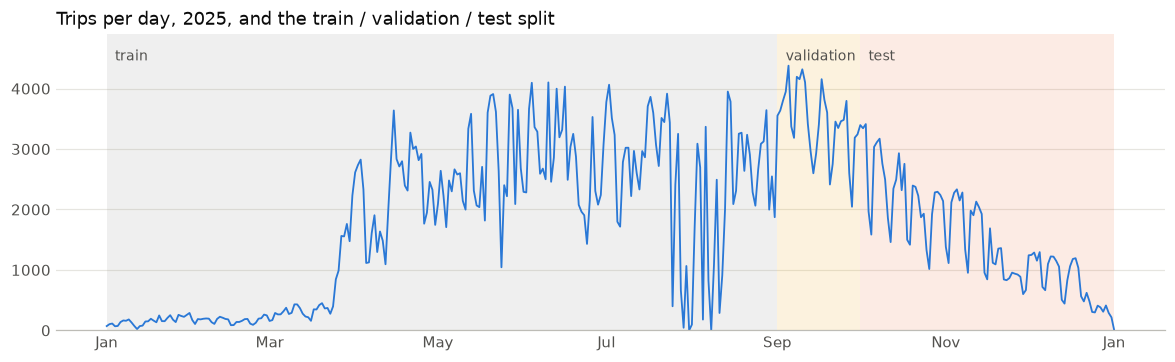

station-hours: train 571,935, validation 74,880, test 228,972


In [41]:
daily_all = hours.groupby("date")["pickups"].sum()
daily_all.index = pd.to_datetime(daily_all.index)
fig, ax = plt.subplots(figsize=(13, 3.5))
periods = [("train", "2025-01-01", "2025-09-01", GRAY), ("validation", "2025-09-01", "2025-10-01", YELLOW),
           ("test", "2025-10-01", "2026-01-01", ORANGE)]
for label, begin, finish, color in periods:
    ax.axvspan(pd.Timestamp(begin), pd.Timestamp(finish), color=color, alpha=0.13, lw=0)
    ax.text(pd.Timestamp(begin) + pd.Timedelta(days=3), daily_all.max() * 1.02, label, color=INK2, fontsize=9)
ax.plot(daily_all.index, daily_all.values, color=BLUE, lw=1.2)
ax.set_ylim(0, daily_all.max() * 1.12)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_title("Trips per day, 2025, and the train / validation / test split")
plt.show()
print(f"station-hours: train {len(train):,}, validation {len(valid):,}, test {len(test):,}")

The test period (autumn and early winter) is harder than a random split:
demand is falling, and the training data contains no autumn at all.

### Baselines: what the model has to beat
[prediction/baselines.py](../prediction/baselines.py)

| Baseline | Forecast for station s, hour T |
|---|---|
| historical mean | mean of station s at the same weekday and hour, Jan–Sep |
| last week | the count at the same hour one week earlier |
| 4-week mean | mean of the same hour over the last 4 weeks |

They do not depend on the horizon.

### The model
[prediction/model.py](../prediction/model.py): **LightGBM**, one model for all stations
(`station` is a categorical feature) and one per target (pickups, returns) and horizon.
Its objective is **Poisson**, because the targets are small counts.

### Metrics, per station-hour on the test period
- **MAE**: mean absolute error, in bikes. 0.5 = off by half a bike per station-hour on average.
- **RMSE**: like MAE, but punishes large misses more.
- **WAPE**: total absolute error / total trips.
- **bias**: total forecast / total trips − 1. Positive means the method predicts too many trips.
- **net flow** (returns − pickups) is scored too, because a station empties when net flow stays negative.
  Only MAE and RMSE for net flow: summed over all station-hours it is close to 0
  (returns and pickups cancel out), so WAPE and bias, which divide by that total, mean nothing.

One table per horizon (1, 3, 6, 24 h) with all metrics; the charts show how MAE and bias change with the horizon.


Horizon 1 h: all metrics per station-hour, test Oct–Dec 2025


MAE   RMSE  WAPE  bias
target   method                                   
pickups  historical mean  0.643  1.072  107%  +33%
         last week        0.602  1.212  100%  +14%
         4-week mean      0.583  1.050   97%  +34%
         LightGBM         0.470  0.830   78%   +5%
returns  historical mean  0.640  1.072  107%  +33%
         last week        0.591  1.197   98%  +14%
         4-week mean      0.577  1.045   96%  +34%
         LightGBM         0.479  0.849   80%   +6%
net flow historical mean  0.602  1.069     –     –
         last week        0.778  1.443     –     –
         4-week mean      0.673  1.184     –     –
         LightGBM         0.550  1.018     –     –


Horizon 3 h: all metrics per station-hour, test Oct–Dec 2025


MAE   RMSE  WAPE  bias
target   method                                   
pickups  historical mean  0.643  1.072  107%  +33%
         last week        0.602  1.212  100%  +14%
         4-week mean      0.583  1.050   97%  +34%
         LightGBM         0.489  0.859   81%  +10%
returns  historical mean  0.640  1.072  107%  +33%
         last week        0.591  1.197   98%  +14%
         4-week mean      0.577  1.045   96%  +34%
         LightGBM         0.493  0.864   82%  +12%
net flow historical mean  0.602  1.069     –     –
         last week        0.778  1.443     –     –
         4-week mean      0.673  1.184     –     –
         LightGBM         0.556  1.036     –     –


Horizon 6 h: all metrics per station-hour, test Oct–Dec 2025


MAE   RMSE  WAPE  bias
target   method                                   
pickups  historical mean  0.643  1.072  107%  +33%
         last week        0.602  1.212  100%  +14%
         4-week mean      0.583  1.050   97%  +34%
         LightGBM         0.492  0.863   82%  +11%
returns  historical mean  0.640  1.072  107%  +33%
         last week        0.591  1.197   98%  +14%
         4-week mean      0.577  1.045   96%  +34%
         LightGBM         0.492  0.863   82%  +12%
net flow historical mean  0.602  1.069     –     –
         last week        0.778  1.443     –     –
         4-week mean      0.673  1.184     –     –
         LightGBM         0.557  1.034     –     –


Horizon 24 h: all metrics per station-hour, test Oct–Dec 2025


MAE   RMSE  WAPE  bias
target   method                                   
pickups  historical mean  0.643  1.072  107%  +33%
         last week        0.602  1.212  100%  +14%
         4-week mean      0.583  1.050   97%  +34%
         LightGBM         0.502  0.874   84%  +14%
returns  historical mean  0.640  1.072  107%  +33%
         last week        0.591  1.197   98%  +14%
         4-week mean      0.577  1.045   96%  +34%
         LightGBM         0.500  0.869   83%  +15%
net flow historical mean  0.602  1.069     –     –
         last week        0.778  1.443     –     –
         4-week mean      0.673  1.184     –     –
         LightGBM         0.559  1.038     –     –

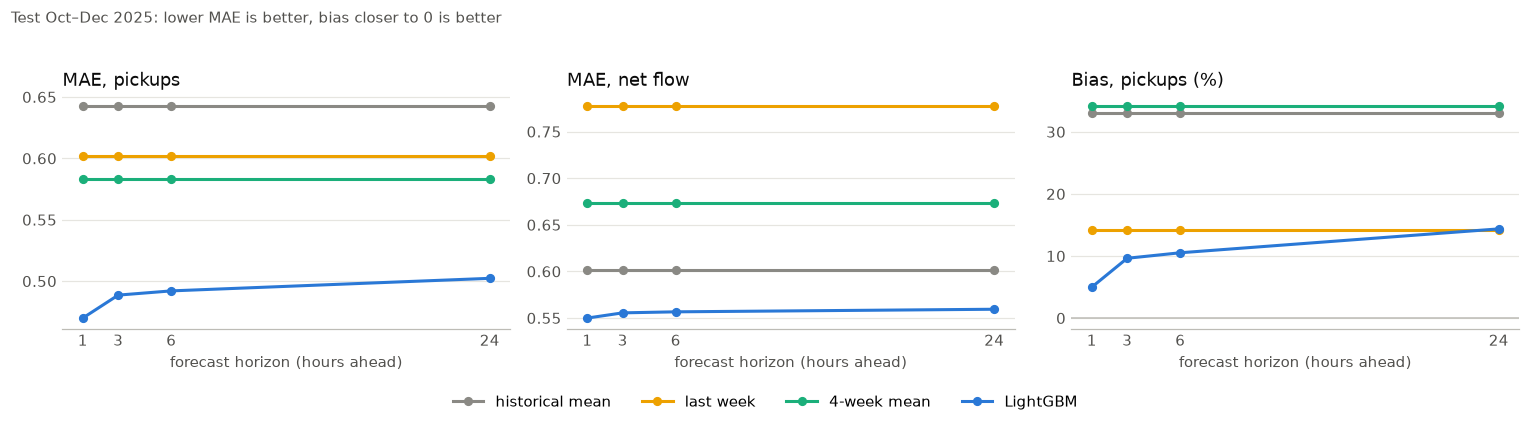

In [42]:
metrics = pd.read_csv(CACHE / "metrics.csv")
names = {"historical_mean": "historical mean", "last_week": "last week", "mean_4w": "4-week mean", "lightgbm": "LightGBM"}
targets = {"pickups": "pickups", "returns": "returns", "net_flow": "net flow"}
metrics["method"] = metrics["method"].map(names)
metrics["target"] = metrics["target"].map(targets)

# All metrics, one table per horizon. Net flow has no WAPE or bias: its total is close to 0
# (returns and pickups cancel out over the network), so dividing by it means nothing.
# Baselines ignore the horizon, so their rows are the same in every table.
order = pd.MultiIndex.from_product([targets.values(), names.values()], names=["target", "method"])
for horizon in sorted(metrics["horizon"].unique()):
    table = metrics[metrics["horizon"] == horizon].set_index(["target", "method"])[["mae", "rmse", "wape", "bias"]].reindex(order)
    shown = pd.DataFrame({
        "MAE": table["mae"].map("{:.3f}".format),
        "RMSE": table["rmse"].map("{:.3f}".format),
        "WAPE": table["wape"].map(lambda v: "–" if pd.isna(v) else f"{v:.0%}"),
        "bias": table["bias"].map(lambda v: "–" if pd.isna(v) else f"{v:+.0%}"),
    })
    print(f"\nHorizon {horizon} h: all metrics per station-hour, test Oct–Dec 2025")
    display(shown)

# How MAE and bias change with the horizon (baselines are flat: they ignore the horizon).
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (target, metric, title) in zip(axes, [("pickups", "mae", "MAE, pickups"), ("net flow", "mae", "MAE, net flow"),
                                              ("pickups", "bias", "Bias, pickups")]):
    part = metrics[metrics["target"] == target].pivot(index="method", columns="horizon", values=metric)
    for label, color in zip(names.values(), [GRAY, YELLOW, AQUA, BLUE]):
        values = part.loc[label] * (100 if metric == "bias" else 1)
        ax.plot(values.index, values.values, color=color, lw=2, marker="o", ms=5, label=label)
    ax.set_xticks(part.columns)
    ax.set_xlabel("forecast horizon (hours ahead)")
    ax.set_title(title + (" (%)" if metric == "bias" else ""))
    if metric == "bias":
        ax.axhline(0, color="#bdbcb6", lw=1)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4)
fig.suptitle("Test Oct–Dec 2025: lower MAE is better, bias closer to 0 is better", x=0.01, ha="left", color=INK2, fontsize=10)
plt.tight_layout(rect=(0, 0.08, 1, 0.95))
plt.show()

**Insights**
- LightGBM is best on **every** metric and target. Returns behave like pickups.
- **RMSE** tells a different story from MAE for "last week": its MAE beats the historical
  mean, but its RMSE is the worst (1.21). Copying one noisy week sometimes misses by a lot;
  averages don't.
- **WAPE ≈ 80 %** per station-hour sounds bad, but single hours are mostly noise (next section).
  Summed over 6 hours or a day, it drops a lot.
- **Bias**: all baselines over-forecast by about a third in autumn; LightGBM by +5 % (1 h) to +14 % (24 h),
  because recent hours let it notice that demand is falling.
- **Net flow** is harder: errors of pickups and returns add up. The historical mean becomes the best
  baseline there (its smooth averages cancel out better), and LightGBM's lead shrinks to about 8 %
  (0.556 vs 0.602 at 3 h).

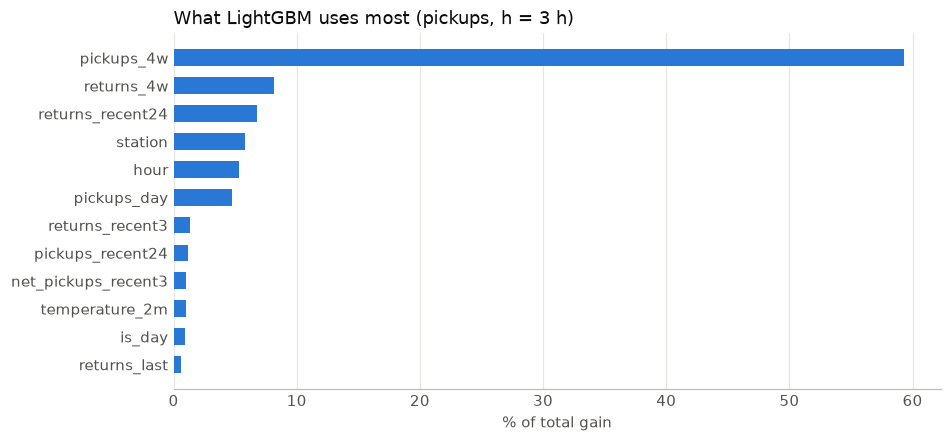

In [43]:
importance = pd.read_csv(CACHE / "importance.csv")
top = importance[(importance["target"] == "pickups") & (importance["horizon"] == 3)].nlargest(12, "gain_share")[::-1]
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(top["feature"], top["gain_share"] * 100, color=BLUE, height=0.6)
ax.set_xlabel("% of total gain")
ax.set_title("What LightGBM uses most (pickups, h = 3 h)")
ax.grid(axis="x", color=GRID)
ax.grid(axis="y", visible=False)
plt.show()

### How good is "0.49"? The noise floor and longer windows

Even a perfect model, one that knew each station's true rate, would be wrong on single
hours, because the actual count is random around that rate (Poisson). Below:
the error such a perfect model would still have, and the errors when hours are
summed into 6-hour blocks and days, which is closer to what an operator plans with.

In [44]:
from scipy.stats import poisson

predictions = pd.read_csv(CACHE / "test_predictions_h3.csv.gz")
predictions["hour_utc"] = pd.to_datetime(predictions["hour_utc"], utc=True)
rate = predictions["pickups_lightgbm"].to_numpy()
k = np.arange(60)[:, None]
noise_floor = (poisson.pmf(k, rate) * np.abs(k - rate)).sum(axis=0).mean()
print(f"LightGBM MAE {np.abs(predictions['pickups'] - rate).mean():.3f}; perfect-rate model ≈ {noise_floor:.3f}")

local = predictions["hour_utc"].dt.tz_convert(TZ)
methods = {"LightGBM": "pickups_lightgbm", "4-week mean": "pickups_mean_4w", "historical mean": "pickups_historical_mean"}
rows = {}
for label, key in [("1 hour", local), ("6-hour block", local.dt.floor("6h")), ("day", local.dt.floor("D"))]:
    window = predictions.groupby([predictions["station"], key])[["pickups", *methods.values()]].sum()
    rows[label] = {name: (window[column] - window["pickups"]).abs().sum() / window["pickups"].sum() for name, column in methods.items()}
    rows[label]["mean pickups"] = window["pickups"].mean()
wape = pd.DataFrame(rows).T
shown = wape[list(methods)].map("{:.0%}".format)
shown.insert(0, "mean pickups", wape["mean pickups"].map("{:.1f}".format))
print("WAPE per station, by window (h = 3 forecasts summed)")
display(shown)

LightGBM MAE 0.489; perfect-rate model ≈ 0.473
WAPE per station, by window (h = 3 forecasts summed)


,mean pickups,LightGBM,4-week mean,historical mean
1 hour,0.6,81%,97%,107%
6-hour block,3.6,38%,54%,72%
day,14.4,22%,41%,61%


**Takeaways**
- LightGBM beats the best baseline by **14–19 %** in MAE at every horizon, and in every
  test month. Its error grows only slowly with the horizon.
- On single hours it is already close to the noise floor. Better models or more data
  cannot lower that much. Summed over 6 hours or a day, the forecast is much more
  accurate (about 38 % and 22 % WAPE), and that is what rebalancing needs.
- All methods over-forecast in autumn because demand falls and the training data
  has no autumn. 2023–2024 data would fix exactly this.

**Limitations to keep in mind**
- *Censored demand*: when a station is empty, wanted trips are not recorded, so true
  demand at often-empty stations is underestimated.
- *Observed weather* instead of forecasts makes the scores slightly optimistic.
- *Live use*: the strongest features need recent trips per station, which the live API
  does not give. A deployable model must use poller counts instead (next step).
- The 6-hour and day windows above sum forecasts made 3 h ahead. A true "from now until
  18:00" test needs all horizons 1–6 h (next step).